In [1]:
from pathlib import Path
import sys

# Locate the project folder automatically
ROOT = Path.cwd().resolve()

if not (ROOT / "src" / "model_setup.py").exists():
    ROOT = ROOT.parent

if not (ROOT / "src" / "model_setup.py").exists():
    raise FileNotFoundError(
        "Project folder not found. Check your working directory."
    )

sys.path.insert(0, str(ROOT))

from src.data_preparation import load_training_bundle
from src.model_setup import make_model_pipeline, shared_cv

# Load the shared training data
X_train, y_train, metadata = load_training_bundle(ROOT)

# Use the same 5-fold cross-validation as Member 2
cv = shared_cv(metadata)

print("Training data:", X_train.shape)
print("Target data:", y_train.shape)
print("CV folds:", cv.get_n_splits())
print("\nTarget distribution:")
print(y_train.value_counts())


Training data: (202795, 21)
Target data: (202795,)
CV folds: 5

Target distribution:
HeartDiseaseorAttack
0    183698
1     19097
Name: count, dtype: int64


In [2]:

from sklearn.ensemble import RandomForestClassifier

rf_model = make_model_pipeline(
    RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    kind="tree"
)

print("Random Forest model created successfully!")
print(rf_model.named_steps["model"])


Random Forest model created successfully!
RandomForestClassifier(n_jobs=-1, random_state=42)


In [3]:

import pandas as pd
from sklearn.model_selection import cross_validate

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "Average_Precision": "average_precision"
}

rf_cv_results = cross_validate(
    estimator=rf_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

rf_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean Validation Score": [
        rf_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        rf_cv_results[f"test_{metric}"].std()
        for metric in scoring
    ]
})

print("Random Forest Baseline Results:")
display(rf_summary.round(4))


Random Forest Baseline Results:


,Metric,Mean Validation Score,Standard Deviation
0,Accuracy,0.9046,0.0011
1,Precision,0.4703,0.0206
2,Recall,0.1015,0.0046
3,F1,0.1669,0.0074
4,ROC_AUC,0.8185,0.0034
5,Average_Precision,0.3171,0.0069


In [4]:

output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

rf_summary.to_csv(
    output_dir / "random_forest_baseline.csv",
    index=False
)

print("Random Forest baseline results saved!")


Random Forest baseline results saved!


In [5]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

# Create a new Random Forest pipeline
rf_tuning_pipeline = make_model_pipeline(
    RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    kind="tree"
)

# Hyperparameters to investigate
param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 20, 30, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.5],
    "model__class_weight": [None, "balanced"]
}

# Search for suitable parameters
rf_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=2,
    refit=True
)

rf_search.fit(X_train, y_train)

print("Best hyperparameters:")
print(rf_search.best_params_)

print("\nBest cross-validation Average Precision:")
print(round(rf_search.best_score_, 4))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END model__class_weight=balanced, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200; total time=  23.7s
[CV] END model__class_weight=balanced, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200; total time=  22.4s
[CV] END model__class_weight=balanced, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200; total time=  21.7s
[CV] END model__class_weight=balanced, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200; total time=  23.8s
[CV] END model__class_weight=balanced, model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5, model__min_samples_split=2, model__n_estimators=200; total time=  24.5s
[CV] END 

In [6]:

import json

# Create the output folder
output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

# Save all tuning results
tuning_results = pd.DataFrame(rf_search.cv_results_)
tuning_results.to_csv(
    output_dir / "random_forest_tuning_results.csv",
    index=False
)

# Save the best parameters
with open(
    output_dir / "random_forest_best_params.json",
    "w"
) as file:
    json.dump(rf_search.best_params_, file, indent=4)

print("Hyperparameter tuning results saved!")


Hyperparameter tuning results saved!


In [7]:

# CELL 7: Inspect available models and files

from pathlib import Path

print("Best Random Forest pipeline:")
print(rf_search.best_estimator_)

print("\nMember 2 result files:")
member2_dir = ROOT / "results" / "member2"

if member2_dir.exists():
    for file in sorted(member2_dir.rglob("*")):
        if file.is_file():
            print(file.relative_to(ROOT))
else:
    print("Member 2 results folder not found.")

print("\nShared source files:")
src_dir = ROOT / "src"

for file in sorted(src_dir.glob("*.py")):
    print(file.relative_to(ROOT))


Best Random Forest pipeline:
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['BMI', 'MentHlth',
                                                   'PhysHlth']),
                                                 ('binary',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['HighBP', 'HighChol',
                                                   'CholCheck', 'Smoker',
                                                   'Stroke', 'PhysActivity',
                                                   'Fruits', 'Veggies',
                                                   'HvyAlcoholConsump',
                                           

In [8]:

from sklearn.linear_model import LogisticRegression

# Recreate Member 2's optimised Logistic Regression
best_lr = make_model_pipeline(
    LogisticRegression(
        C=0.1,
        solver="lbfgs",
        class_weight=None,
        max_iter=2000,
        random_state=42
    ),
    kind="linear"
)

# Use the best Random Forest from your tuning
best_rf = rf_search.best_estimator_

print("Optimised Logistic Regression:")
print(best_lr.named_steps["model"])

print("\nOptimised Random Forest:")
print(best_rf.named_steps["model"])


Optimised Logistic Regression:
LogisticRegression(C=0.1, max_iter=2000, random_state=42)

Optimised Random Forest:
RandomForestClassifier(max_depth=10, max_features=0.5, min_samples_split=5,
                       n_jobs=-1, random_state=42)


In [9]:

from sklearn.ensemble import VotingClassifier

# Combine Logistic Regression and Random Forest
ensemble_model = VotingClassifier(
    estimators=[
        ("logistic_regression", best_lr),
        ("random_forest", best_rf)
    ],
    voting="soft",
    weights=[1, 1],
    n_jobs=1
)

print("Soft Voting Ensemble created successfully!")
print(ensemble_model)


Soft Voting Ensemble created successfully!
VotingClassifier(estimators=[('logistic_regression',
                              Pipeline(steps=[('preprocess',
                                               ColumnTransformer(transformers=[('numeric',
                                                                                Pipeline(steps=[('imputer',
                                                                                                 SimpleImputer(strategy='median')),
                                                                                                ('scaler',
                                                                                                 StandardScaler())]),
                                                                                ['BMI',
                                                                                 'MentHlth',
                                                                                 'PhysHlth']),
           

In [10]:

from sklearn.model_selection import cross_validate
import pandas as pd

ensemble_scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "Average_Precision": "average_precision"
}

ensemble_cv_results = cross_validate(
    estimator=ensemble_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=ensemble_scoring,
    n_jobs=1,
    return_train_score=False
)

ensemble_summary = pd.DataFrame({
    "Metric": list(ensemble_scoring.keys()),
    "Mean Validation Score": [
        ensemble_cv_results[f"test_{metric}"].mean()
        for metric in ensemble_scoring
    ],
    "Standard Deviation": [
        ensemble_cv_results[f"test_{metric}"].std()
        for metric in ensemble_scoring
    ]
})

print("Soft Voting Ensemble Results:")
display(ensemble_summary.round(4))


Soft Voting Ensemble Results:


,Metric,Mean Validation Score,Standard Deviation
0,Accuracy,0.9079,0.0008
1,Precision,0.5659,0.0173
2,Recall,0.0970,0.0017
3,F1,0.1656,0.0028
4,ROC_AUC,0.8490,0.0038
5,Average_Precision,0.3723,0.0076


In [11]:

output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

ensemble_summary.to_csv(
    output_dir / "soft_voting_ensemble.csv",
    index=False
)

print("Ensemble results saved successfully!")


Ensemble results saved successfully!


In [12]:

# CELL 12: Train and save final models for Member 4

from joblib import dump

output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

# The RandomizedSearchCV best model was already
# refitted on the complete training dataset.
final_rf = rf_search.best_estimator_

# Fit the ensemble on the complete training dataset.
# Do not use the held-out test dataset here.
ensemble_model.fit(X_train, y_train)

# Save trained models
dump(
    final_rf,
    output_dir / "random_forest_optimised.joblib"
)

dump(
    ensemble_model,
    output_dir / "soft_voting_ensemble.joblib"
)

print("Both trained models saved successfully!")


Both trained models saved successfully!


In [13]:

# CELL 13: Create Member 3 model comparison

import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Random Forest (Baseline)",
        "Random Forest (Optimised)",
        "Soft Voting Ensemble"
    ],
    "Average Precision": [
        0.3171,
        rf_search.best_score_,
        ensemble_summary.loc[
            ensemble_summary["Metric"] == "Average_Precision",
            "Mean Validation Score"
        ].iloc[0]
    ]
})

comparison.to_csv(
    output_dir / "member3_model_comparison.csv",
    index=False
)

print("Member 3 Model Comparison:")
display(comparison.round(4))

print("\nComparison saved successfully!")


Member 3 Model Comparison:


,Model,Average Precision
0,Random Forest (Baseline),0.3171
1,Random Forest (Optimised),0.3653
2,Soft Voting Ensemble,0.3723



Comparison saved successfully!


In [14]:

# CELL 14: Random Forest Feature Importance

import pandas as pd

# Retrieve the optimised Random Forest pipeline
best_rf = rf_search.best_estimator_

# Get the preprocessing and Random Forest components
preprocessor = best_rf.named_steps["preprocess"]
forest = best_rf.named_steps["model"]

# Retrieve feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Retrieve feature importance scores
importance_scores = forest.feature_importances_

# Create a table
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort from most important to least important
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Most Important Features:")
display(feature_importance_df.head(15).round(4))


Top 15 Most Important Features:


,Feature,Importance
0,ordinal__GenHlth,0.2401
1,ordinal__Age,0.1678
2,binary__Stroke,0.0990
3,binary__HighBP,0.0856
4,binary__DiffWalk,0.0645
5,binary__Sex,0.0628
6,binary__HighChol,0.0610
7,numeric__BMI,0.0465
8,numeric__PhysHlth,0.0310
9,ordinal__Income,0.0274


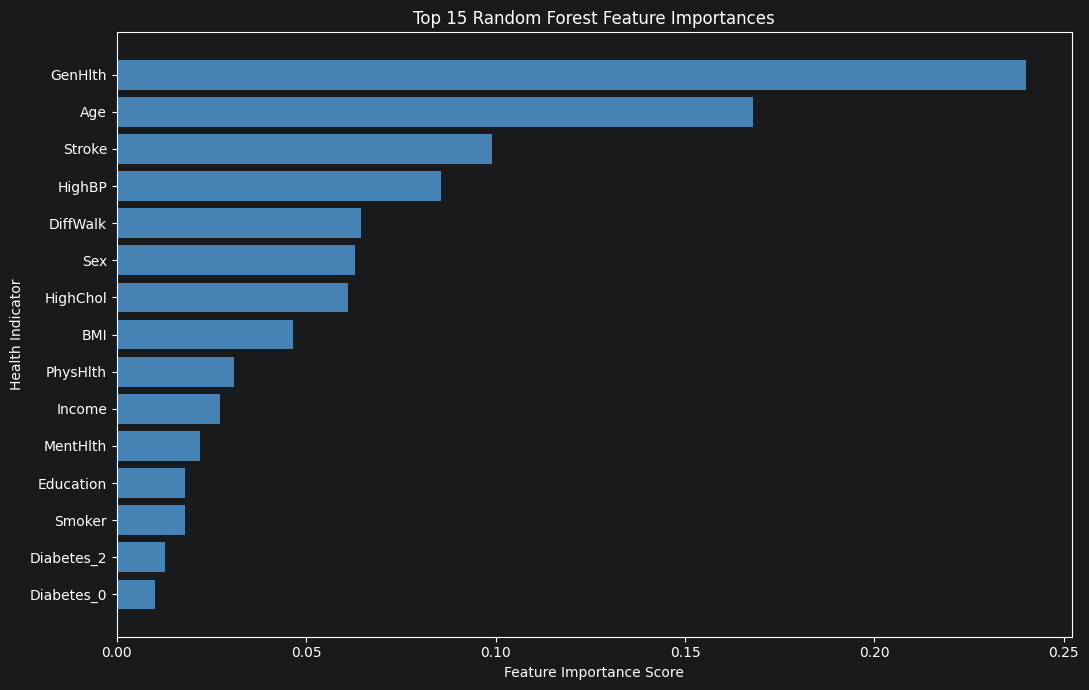

Feature importance graph and CSV saved successfully!


In [15]:

# CELL 15: Plot and save Random Forest Feature Importance

import matplotlib.pyplot as plt

# Select the 15 most important features
top_features = feature_importance_df.head(15).copy()

# Remove preprocessing prefixes to make names easier to read
top_features["Feature"] = top_features["Feature"].str.split(
    "__", n=1
).str[-1]

# Plot from lowest to highest importance
top_features = top_features.sort_values("Importance")

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    color="steelblue"
)

plt.xlabel("Feature Importance Score")
plt.ylabel("Health Indicator")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()

# Save graph and full feature importance table
output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

feature_importance_df.to_csv(
    output_dir / "random_forest_feature_importance.csv",
    index=False
)

plt.show()

print("Feature importance graph and CSV saved successfully!")


In [16]:

# CELL 16: Evaluate optimised Random Forest
# using the same 5-fold cross-validation

from sklearn.model_selection import cross_validate
import pandas as pd

optimised_rf_cv = cross_validate(
    estimator=best_rf,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

optimised_rf_summary = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean Training Score": [
        optimised_rf_cv[f"train_{metric}"].mean()
        for metric in scoring
    ],
    "Mean Validation Score": [
        optimised_rf_cv[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Validation Standard Deviation": [
        optimised_rf_cv[f"test_{metric}"].std()
        for metric in scoring
    ]
})

# Calculate training-validation differences
optimised_rf_summary["Train-Validation Gap"] = (
    optimised_rf_summary["Mean Training Score"]
    - optimised_rf_summary["Mean Validation Score"]
)

display(optimised_rf_summary.round(4))

# Save results
output_dir = ROOT / "results" / "member3"

optimised_rf_summary.to_csv(
    output_dir / "random_forest_optimised_cv.csv",
    index=False
)

print("Optimised Random Forest evaluation saved successfully!")


,Metric,Mean Training Score,Mean Validation Score,Validation Standard Deviation,Train-Validation Gap
0,Accuracy,0.9141,0.9075,0.0008,0.0067
1,Precision,0.8095,0.5716,0.0210,0.2379
2,Recall,0.1154,0.0706,0.0033,0.0448
3,F1,0.2020,0.1257,0.0053,0.0764
4,ROC_AUC,0.8731,0.8467,0.0037,0.0264
5,Average_Precision,0.4789,0.3653,0.0089,0.1135


Optimised Random Forest evaluation saved successfully!


Baseline vs Optimised Random Forest:


,Metric,Baseline,Optimised,Difference
0,Accuracy,0.9046,0.9075,0.0029
1,Precision,0.4703,0.5716,0.1013
2,Recall,0.1015,0.0706,-0.0308
3,F1,0.1669,0.1257,-0.0412
4,ROC_AUC,0.8185,0.8467,0.0282
5,Average_Precision,0.3171,0.3653,0.0482


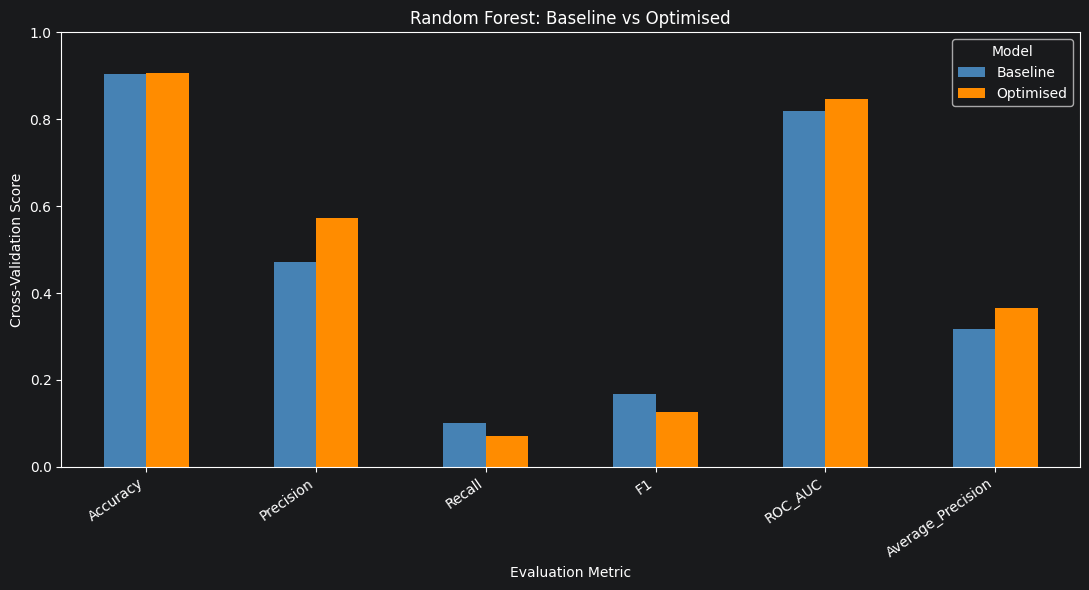

Comparison table and graph saved successfully!


In [17]:

# CELL 17: Compare baseline and optimised Random Forest

import pandas as pd
import matplotlib.pyplot as plt

# Prepare baseline results
baseline_comparison = rf_summary[
    ["Metric", "Mean Validation Score"]
].rename(columns={
    "Mean Validation Score": "Baseline"
})

# Prepare optimised results
optimised_comparison = optimised_rf_summary[
    ["Metric", "Mean Validation Score"]
].rename(columns={
    "Mean Validation Score": "Optimised"
})

# Combine results
rf_comparison = baseline_comparison.merge(
    optimised_comparison,
    on="Metric"
)

# Calculate improvements or decreases
rf_comparison["Difference"] = (
    rf_comparison["Optimised"] -
    rf_comparison["Baseline"]
)

print("Baseline vs Optimised Random Forest:")
display(rf_comparison.round(4))

# Save comparison CSV
rf_comparison.to_csv(
    output_dir / "random_forest_baseline_vs_optimised.csv",
    index=False
)

# Plot comparison
ax = rf_comparison.set_index("Metric")[
    ["Baseline", "Optimised"]
].plot(
    kind="bar",
    figsize=(11, 6),
    color=["steelblue", "darkorange"]
)

plt.title("Random Forest: Baseline vs Optimised")
plt.ylabel("Cross-Validation Score")
plt.xlabel("Evaluation Metric")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    output_dir / "random_forest_baseline_vs_optimised.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison table and graph saved successfully!")


In [18]:

# CELL 18: Verify Member 2's optimised model results

import pandas as pd

member2_dir = ROOT / "results" / "member2"

lr_results = pd.read_csv(
    member2_dir / "logistic_regression_optimised.csv"
)

dt_results = pd.read_csv(
    member2_dir / "decision_tree_optimised.csv"
)

print("Optimised Logistic Regression Results:")
display(lr_results)

print("\nOptimised Decision Tree Results:")
display(dt_results)


Optimised Logistic Regression Results:


,Metric,Mean,Std
0,Accuracy,0.907436,0.001201
1,Precision,0.537486,0.018554
2,Recall,0.122182,0.005620
3,F1,0.199085,0.008570
4,ROC_AUC,0.846466,0.003913
5,Average_Precision,0.368867,0.006616



Optimised Decision Tree Results:


,Metric,Mean,Std
0,Accuracy,0.906579,0.000688
1,Precision,0.523256,0.009686
2,Recall,0.088901,0.008102
3,F1,0.151841,0.011916
4,ROC_AUC,0.834016,0.003750
5,Average_Precision,0.340700,0.005973


In [19]:

# CELL 19: Final model selection comparison

import pandas as pd

# Extract Member 2's scores from their saved CSV files
def get_score(results, metric):
    return float(
        results.loc[
            results["Metric"] == metric,
            "Mean"
        ].iloc[0]
    )

# Extract our Random Forest and ensemble scores
def get_our_score(results, metric):
    return float(
        results.loc[
            results["Metric"] == metric,
            "Mean Validation Score"
        ].iloc[0]
    )

model_selection = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Decision Tree",
        "Soft Voting Ensemble"
    ],
    "Average Precision": [
        get_score(lr_results, "Average_Precision"),
        get_our_score(optimised_rf_summary, "Average_Precision"),
        get_score(dt_results, "Average_Precision"),
        get_our_score(ensemble_summary, "Average_Precision")
    ],
    "ROC-AUC": [
        get_score(lr_results, "ROC_AUC"),
        get_our_score(optimised_rf_summary, "ROC_AUC"),
        get_score(dt_results, "ROC_AUC"),
        get_our_score(ensemble_summary, "ROC_AUC")
    ],
    "Recall": [
        get_score(lr_results, "Recall"),
        get_our_score(optimised_rf_summary, "Recall"),
        get_score(dt_results, "Recall"),
        get_our_score(ensemble_summary, "Recall")
    ]
})

# Add model-selection status
model_selection["Selection"] = [
    "Selected for ensemble",
    "Selected for ensemble",
    "Excluded from ensemble",
    "Ensemble model"
]

print("Final Model Selection:")
display(model_selection.round(4))

# Save CSV
output_dir = ROOT / "results" / "member3"
output_dir.mkdir(parents=True, exist_ok=True)

model_selection.to_csv(
    output_dir / "model_selection_comparison.csv",
    index=False
)

print("Model selection comparison saved successfully!")


Final Model Selection:


,Model,Average Precision,ROC-AUC,Recall,Selection
0,Logistic Regression,0.3689,0.8465,0.1222,Selected for ensemble
1,Random Forest,0.3653,0.8467,0.0706,Selected for ensemble
2,Decision Tree,0.3407,0.8340,0.0889,Excluded from ensemble
3,Soft Voting Ensemble,0.3723,0.8490,0.0970,Ensemble model


Model selection comparison saved successfully!


In [20]:

# CELL 20: Random Forest Computational Efficiency

import pandas as pd

efficiency_comparison = pd.DataFrame({
    "Model": [
        "Random Forest (Baseline)",
        "Random Forest (Optimised)"
    ],
    "Mean Fit Time (seconds)": [
        rf_cv_results["fit_time"].mean(),
        optimised_rf_cv["fit_time"].mean()
    ],
    "Fit Time Std (seconds)": [
        rf_cv_results["fit_time"].std(),
        optimised_rf_cv["fit_time"].std()
    ],
    "Mean Score Time (seconds)": [
        rf_cv_results["score_time"].mean(),
        optimised_rf_cv["score_time"].mean()
    ]
})

print("Random Forest Computational Efficiency:")
display(efficiency_comparison.round(3))

efficiency_comparison.to_csv(
    output_dir / "random_forest_computational_efficiency.csv",
    index=False
)

print("Computational efficiency results saved successfully!")


Random Forest Computational Efficiency:


,Model,Mean Fit Time (seconds),Fit Time Std (seconds),Mean Score Time (seconds)
0,Random Forest (Baseline),6.931,0.457,0.455
1,Random Forest (Optimised),10.679,0.991,0.189


Computational efficiency results saved successfully!
